# Emanuele Imperiali 

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from scipy.stats import norm

tickers = ["MSFT", "AAPL", "GOOGL"]
V = 1_000_000
alpha = 0.95

# 1
Download daily closing prices for MSFT, AAPL, and GOOGL
from May 23, 2024 to May 22, 2026.

**Pseudocode**
1. Download historical closing prices from Yahoo Finance.
2. Select the three stocks and remove missing observations.
3. Display the first and last five observations.
4. Report the total number of observations.

In [7]:
prices = yf.download(
    tickers,
    start="2024-05-23",
    end="2026-05-23",
    auto_adjust=False,
    progress=False
)["Close"]

prices = prices[tickers].dropna()

print("First five observations:")
display(prices.head())

print("Last five observations:")
display(prices.tail())

print("Total observations:", len(prices))

First five observations:


Ticker,MSFT,AAPL,GOOGL
Date,,,
2024-05-23,427.000000,186.880005,173.550003
2024-05-24,430.160004,189.979996,174.990005
2024-05-28,430.320007,189.990005,176.399994
2024-05-29,429.170013,190.289993,175.899994
2024-05-30,414.670013,191.289993,172.110001


Last five observations:


Ticker,MSFT,AAPL,GOOGL
Date,,,
2026-05-18,423.540009,297.839996,396.940002
2026-05-19,417.420013,298.970001,387.660004
2026-05-20,421.059998,302.250000,388.910004
2026-05-21,419.089996,304.989990,387.660004
2026-05-22,418.570007,308.820007,382.970001


Total observations: 501


# 2

The portfolio is weighted according to the market capitalization
of each stock as of May 22, 2026.

**Pseudocode**
1. Define the market capitalization of each company.
2. Calculate the total market capitalization.
3. Divide each company's capitalization by the total.
4. Calculate the dollar allocation of the $1,000,000 portfolio.

In [10]:
market_caps = np.array([3.109, 4.536, 4.640])

weights = market_caps / market_caps.sum()

allocations = V * weights

portfolio = pd.DataFrame({
    "Market Cap (Trillion USD)": market_caps,
    "Weight": weights,
    "Allocation (USD)": allocations
}, index=tickers)

display(portfolio)

,Market Cap (Trillion USD),Weight,Allocation (USD)
MSFT,3.109,0.253073,253072.853073
AAPL,4.536,0.369231,369230.769231
GOOGL,4.640,0.377696,377696.377696


# 3

Estimate the 95% VaR using the empirical distribution
of historical daily log returns.

**Pseudocode**
1. Compute daily log returns for the three stocks.
2. Apply the full, linear, and quadratic loss operators.
3. Construct the empirical loss distributions.
4. Compute the 95th percentile of each loss distribution.

In [15]:
X = np.log(prices / prices.shift(1)).dropna()

L_full = -V * ((np.exp(X) - 1) @ weights)
L_lin = -V * (X @ weights)
L_quad = -V * ((X + 0.5 * X**2) @ weights)

var_emp = pd.Series({
    "Full": np.quantile(L_full, alpha),
    "Linear": np.quantile(L_lin, alpha),
    "Quadratic": np.quantile(L_quad, alpha)
})

display(var_emp.to_frame("Empirical VaR (USD)"))

,Empirical VaR (USD)
Full,21045.338698
Linear,21418.353814
Quadratic,21040.898072


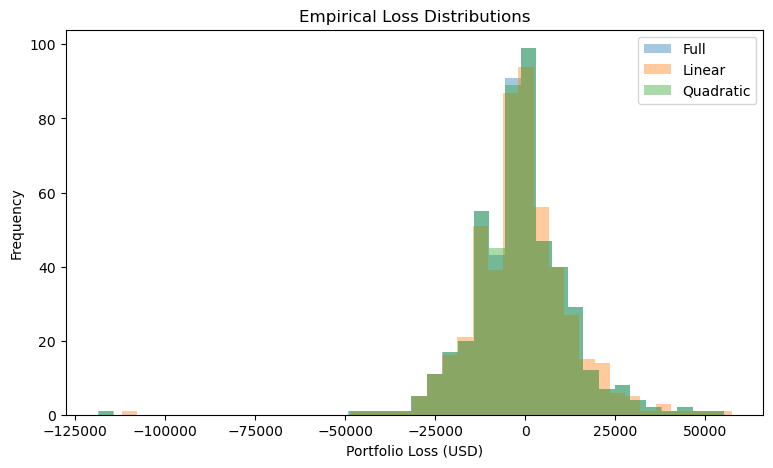

In [17]:
plt.figure(figsize=(9, 5))

plt.hist(L_full, bins=40, alpha=0.4, label="Full")
plt.hist(L_lin, bins=40, alpha=0.4, label="Linear")
plt.hist(L_quad, bins=40, alpha=0.4, label="Quadratic")

plt.xlabel("Portfolio Loss (USD)")
plt.ylabel("Frequency")
plt.title("Empirical Loss Distributions")
plt.legend()
plt.show()

# 4

Estimate the conditional mean vector and covariance matrix
of daily log returns using EWMA.

**Pseudocode**
1. Initialize the mean vector and covariance matrix to zero.
2. Set both decay factors to 0.97.
3. For each daily return observation:
   - Update the covariance matrix using the previous mean.
   - Update the mean vector using the current return.
4. Report the final mean vector and covariance matrix.

In [20]:
lam = 0.97
theta = 0.97

mu = np.zeros(3)
Sigma = np.zeros((3, 3))

for x in X.to_numpy():
    error = x - mu

    Sigma = theta * Sigma + (1 - theta) * np.outer(error, error)
    mu = lam * mu + (1 - lam) * x

print("EWMA Mean:")
display(pd.Series(mu, index=tickers))

print("EWMA Covariance:")
display(pd.DataFrame(Sigma, index=tickers, columns=tickers))

EWMA Mean:


MSFT     0.000473
AAPL     0.003636
GOOGL    0.003306
dtype: float64

EWMA Covariance:


,MSFT,AAPL,GOOGL
MSFT,0.000314,0.000034,0.000003
AAPL,0.000034,0.000193,0.000081
GOOGL,0.000003,0.000081,0.000459


# 5

Estimate the 95% VaR assuming multivariate normally distributed
log returns with the EWMA mean and covariance estimates.

**Pseudocode**
1. Generate 100,000 multivariate normal return vectors.
2. Compute the full and quadratic losses for each simulation.
3. Estimate their VaR using the 95th percentile.
4. For the linear loss, compute portfolio mean and variance.
5. Calculate linear VaR analytically using the normal quantile.

In [23]:
N = 100_000
np.random.seed(42)

X_sim = np.random.multivariate_normal(mu, Sigma, size=N)

L_full_mc = -V * ((np.exp(X_sim) - 1) @ weights)

L_quad_mc = -V * ((X_sim + 0.5 * X_sim**2) @ weights)

var_full_mc = np.quantile(L_full_mc, alpha)
var_quad_mc = np.quantile(L_quad_mc, alpha)

print("Full MC VaR:", var_full_mc)
print("Quadratic MC VaR:", var_quad_mc)

Full MC VaR: 16513.354238898628
Quadratic MC VaR: 16512.262417512236


In [25]:
mu_p = weights @ mu
sigma_p = np.sqrt(weights @ Sigma @ weights)

z = norm.ppf(alpha)

var_lin_analytical = -V * mu_p + z * V * sigma_p

print("Analytical Linear VaR:", var_lin_analytical)

Analytical Linear VaR: 16869.110889564414


In [27]:
var_param = pd.Series({
    "Full": var_full_mc,
    "Linear": var_lin_analytical,
    "Quadratic": var_quad_mc
})

display(var_param.to_frame("Parametric VaR (USD)"))

,Parametric VaR (USD)
Full,16513.354239
Linear,16869.110890
Quadratic,16512.262418


# 6

Compare the empirical and parametric VaR estimates.

**Pseudocode**
1. Combine the empirical and parametric VaR estimates.
2. Calculate the percentage difference between the two methods.
3. Compare the three loss operators.
4. Discuss the effects of distributional assumptions,
   volatility estimation, and nonlinearities.

In [30]:
comparison = pd.DataFrame({
    "Empirical VaR": var_emp,
    "Parametric VaR": var_param
})

comparison["Difference (%)"] = (
    (comparison["Parametric VaR"] / comparison["Empirical VaR"] - 1) * 100
)

display(comparison.round(2))

,Empirical VaR,Parametric VaR,Difference (%)
Full,21045.34,16513.35,-21.53
Linear,21418.35,16869.11,-21.24
Quadratic,21040.90,16512.26,-21.52


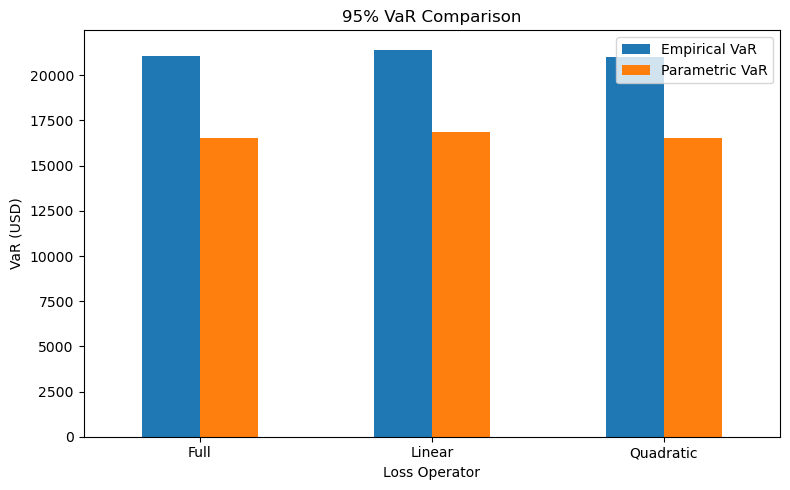

In [32]:
comparison[["Empirical VaR", "Parametric VaR"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("95% VaR Comparison")
plt.ylabel("VaR (USD)")
plt.xlabel("Loss Operator")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The parametric VaR estimates are approximately 21% lower than the empirical estimates across all three loss operators. This difference may be explained by the normality assumption and EWMA estimation, which places greater weight on recent observations. Furthermore, the positive EWMA mean returns contribute to lowering the parametric VaR.

Within each method, the full and quadratic VaR estimates are nearly identical, indicating that the second-order approximation is highly accurate for daily returns. The linear VaR is slightly higher because it neglects the positive quadratic terms.